# 3. Unsupervised learning: clustering

K-means groups observations without labelled answers. Here each artificial observation contains soil moisture and plant height. Cluster numbers are arbitrary: cluster 0 does not inherently mean healthy or unhealthy.

**Setup:** Follow [README.md](README.md) to create a virtual environment,
install all packages and choose the `Python (AGR9027 ML)` kernel. Run all cells
in order. All observations here are artificial; ML is optional for Assessment 2.

Silhouette score: 0.818


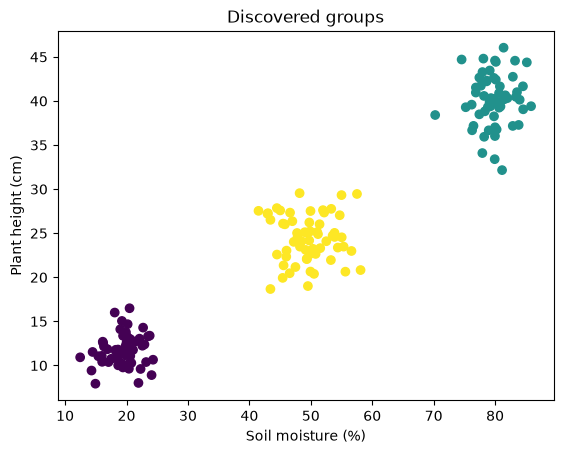

In [3]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import silhouette_score
import joblib
from tempfile import TemporaryDirectory
from pathlib import Path

rng = np.random.default_rng(7)
X = np.vstack([
    rng.normal([20, 12], [3, 2], (60, 2)),
    rng.normal([50, 25], [4, 3], (60, 2)),
    rng.normal([80, 40], [3, 3], (60, 2)),
])  # moisture (%), height (cm)
model = make_pipeline(StandardScaler(), KMeans(n_clusters=3, n_init=10, random_state=7))
groups = model.fit_predict(X)
# Silhouette is computed in the scaled feature space used by k-means.
scaled = model.named_steps["standardscaler"].transform(X)
print("Silhouette score:", round(silhouette_score(scaled, groups), 3))
plt.scatter(X[:, 0], X[:, 1], c=groups, cmap="viridis")
plt.xlabel("Soil moisture (%)")
plt.ylabel("Plant height (cm)")
plt.title("Discovered groups")
plt.show()

## Assign a new observation

The scaler and k-means are saved together, so new inputs receive the same preprocessing. Only load trusted joblib files. The plot shows each training cluster in a different colour and marks the new observation with a star. This is not a classification accuracy: there are no ground-truth labels.

Cluster for [moisture=48, height=24]: 2


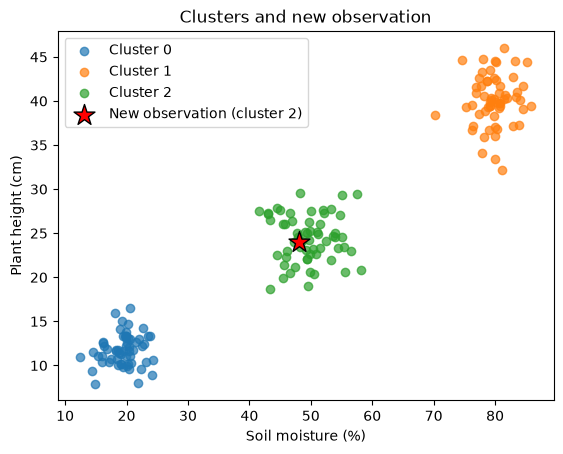

In [4]:
new_observation = np.array([[48, 24]])  # moisture (%), height (cm)
with TemporaryDirectory() as folder:
    path = Path(folder) / "clusters.joblib"
    joblib.dump(model, path)
    loaded_model = joblib.load(path)
    new_group = loaded_model.predict(new_observation)[0]
    print(f"Cluster for [moisture={new_observation[0, 0]}, height={new_observation[0, 1]}]: {new_group}")

# Draw the existing observations, keeping each cluster's label in the legend.
for group in np.unique(groups):
    members = X[groups == group]
    plt.scatter(members[:, 0], members[:, 1], label=f"Cluster {group}", alpha=0.7)
plt.scatter(new_observation[0, 0], new_observation[0, 1],
            marker="*", s=250, c="red", edgecolors="black",
            label=f"New observation (cluster {new_group})", zorder=3)
plt.xlabel("Soil moisture (%)")
plt.ylabel("Plant height (cm)")
plt.title("Clusters and new observation")
plt.legend()
plt.show()

**Try:** In the first code cell, find `KMeans(n_clusters=3, n_init=10, random_state=7)` and change `n_clusters=3` to `n_clusters=2`. Run that cell and the prediction cell again. Compare the number of groups, the plots and the silhouette score with the original result. Then try `n_clusters=4`: does a natural-looking group split into smaller groups? The silhouette score ranges from -1 to 1; higher values generally indicate more compact, separated groups, but do not prove biological meaning. Cluster numbers and colours can change between runs, so compare the positions of points rather than the numeric labels. Use at least 2 clusters for the silhouette calculation.

You can also change `new_observation = np.array([[48, 24]])` in the prediction cell, for example to `[[75, 38]]`, and rerun that cell to see where the star appears and which group the existing model assigns it to.